In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
data = load_wine(as_frame=True)

X = data.data

print("Dataset shape:", X.shape)
X.head()

Dataset shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (178, 13)
Scaled shape: (178, 13)


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled) # This has reduced DATASET

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)

Original shape: (178, 13)
Reduced shape: (178, 2)


### **`explained_variance_ratio_` this returns variance ratio** 

In [5]:
explained_variance = pca.explained_variance_ratio_

print("PC1 variance:", explained_variance[0])
print("PC2 variance:", explained_variance[1])

print(
    "Total explained variance:",
    explained_variance.sum()
)

PC1 variance: 0.3619884809992632
PC2 variance: 0.19207490257008938
Total explained variance: 0.5540633835693526


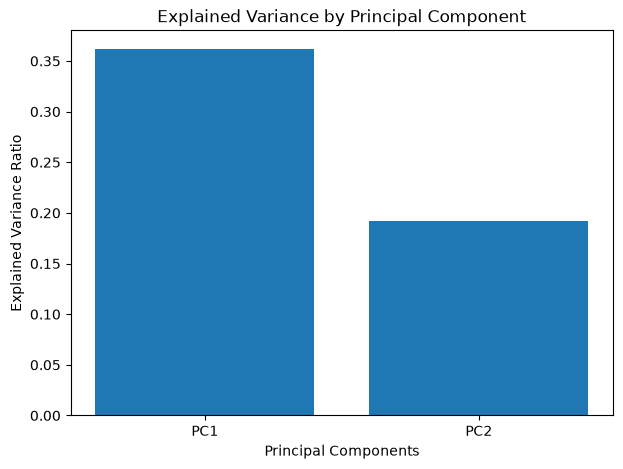

In [7]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["PC1", "PC2"],
    explained_variance
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Component")

plt.show()

#### **PCA( ) without specifying n_components retains all possible principal components.**


In [10]:
pca_full = PCA()

X_pca_full = pca_full.fit_transform(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

cumulative_variance

array([0.36198848, 0.55406338, 0.66529969, 0.73598999, 0.80162293,
       0.85098116, 0.89336795, 0.92017544, 0.94239698, 0.96169717,
       0.97906553, 0.99204785, 1.        ])

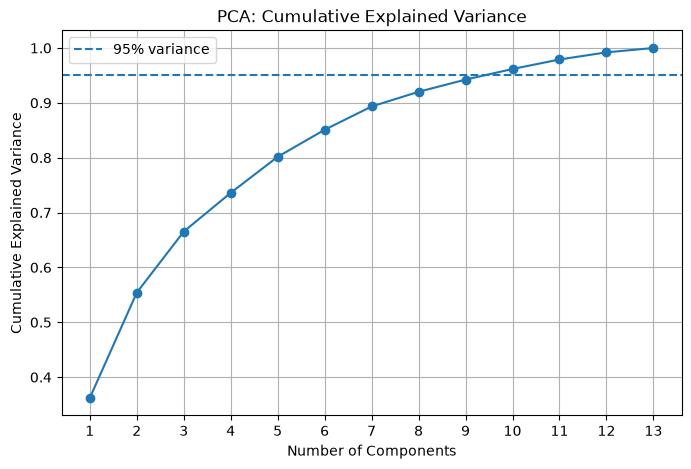

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")

plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True)

plt.show()

In [13]:
pca_95 = PCA(n_components=0.95)

X_pca_95 = pca_95.fit_transform(X_scaled)

print("Original features:", X_scaled.shape[1])
print("Reduced features:", X_pca_95.shape[1])

print(
    "Explained variance:",
    pca_95.explained_variance_ratio_.sum()
)

Original features: 13
Reduced features: 10
Explained variance: 0.9616971684450643


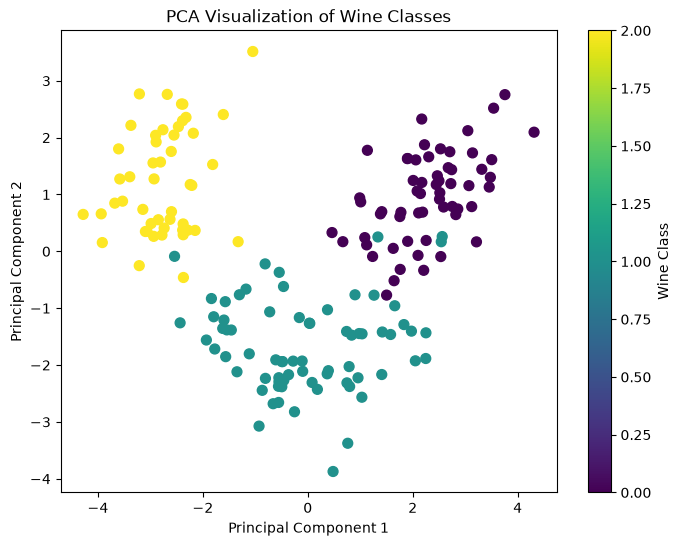

In [15]:
y = data.target

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wine Classes")

plt.colorbar(scatter, label="Wine Class")

plt.show()

#### 1. Each row represents a principal component, and each column corresponds to an original feature.
#### 2. A large absolute weight indicates a stronger contribution to that component, although interpretation should consider the weights collectively.
#### 3. Important: The sign of a component is arbitrary. A negative weight does not automatically mean a feature is unimportant.

In [16]:
components_df = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2"]
)

components_df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
PC1,0.144329,-0.245188,-0.002051,-0.239320,0.141992,0.394661,0.422934,-0.298533,0.313429,-0.088617,0.296715,0.376167,0.286752
PC2,0.483652,0.224931,0.316069,-0.010591,0.299634,0.065040,-0.003360,0.028779,0.039302,0.529996,-0.279235,-0.164496,0.364903


In [ ]:
X_reconstructed = pca.inverse_transform(X_pca)  

# # inverse_transform() maps those components back into the original 13-feature space.

print("Original scaled shape:", X_scaled.shape)
print("Reconstructed shape:", X_reconstructed.shape)

Original scaled shape: (178, 13)
Reconstructed shape: (178, 13)


In [18]:
reconstruction_error = np.mean(
    (X_scaled - X_reconstructed) ** 2
)

print("Reconstruction MSE:", reconstruction_error)

Reconstruction MSE: 0.4459366164306474


In [19]:
print("Original number of features:", X_scaled.shape[1])

print("Number of components selected:", pca_95.n_components_)

print("Explained variance:", pca_95.explained_variance_ratio_.sum())

print("Reduced dataset shape:", X_pca_95.shape)

Original number of features: 13
Number of components selected: 10
Explained variance: 0.9616971684450643
Reduced dataset shape: (178, 10)
